# 02 — Analysis: Q5

Notebook kiểm toán dữ liệu bổ trợ. `abuse_type` mô tả loại abuse theo rule; không được dùng để sửa `label` của bảng chính. Chủ sở hữu tự viết phần kết luận sau khi kiểm tra grain, phép ghép và các bảng kết quả.

## Q5 — Auxiliary dataset consistency audit

**Chủ sở hữu:** Trịnh Tấn Phát — 24127485

**Câu hỏi:** `abuse_type.csv` nhất quán đến đâu với nhãn trong dataset chính khi đối chiếu theo hostname, và kết quả thay đổi thế nào theo quy tắc chuẩn hóa/khử trùng lặp?

**Động lực, người dùng kết quả và quyết định liên quan:** `[chủ sở hữu tự viết]`

Tài liệu nguồn mô tả auxiliary key là URL. Phân tích so sánh ba grain: exact-string URL, normalized URL và hostname sau khi aggregate mỗi phía về một dòng/hostname. Host-level consistency được báo cáo theo định nghĩa strict (mọi URL của hostname đều phishing) và lenient (ít nhất một URL phishing); đây là hai quy ước đo khác nhau để chủ sở hữu thảo luận. `unknown` được giữ như một abuse type có ý nghĩa, không coi là missing label.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

starts = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p for p in starts if (p / "environment.yml").is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Could not locate repository root containing environment.yml.")
sys.path.insert(0, str(PROJECT_ROOT))
from src.data_io import duplicate_summary, load_raw_csv
from src.url_utils import hostname_from_url, normalize_url_key

main_raw = load_raw_csv("vn_compphish.csv")
aux_raw = load_raw_csv("abuse_type.csv")
main = main_raw.copy()
aux = aux_raw.copy()
LABEL_NAMES = {0: "benign", 1: "phishing"}
print("Main / auxiliary rows:", len(main), "/", len(aux))
print("Main / auxiliary exact duplicate rows:", duplicate_summary(main)["duplicate_rows"], "/", duplicate_summary(aux)["duplicate_rows"])
print("Auxiliary duplicate raw URL keys:", duplicate_summary(aux, key="url")["duplicate_key_rows"])
print("Auxiliary abuse-type values (unknown retained):")
display(aux["abuse_type"].value_counts(dropna=False).rename_axis("abuse_type").to_frame("count"))

Main / auxiliary rows: 53116 / 36706
Main / auxiliary exact duplicate rows: 0 / 0
Auxiliary duplicate raw URL keys: 0
Auxiliary abuse-type values (unknown retained):


,count
abuse_type,
unknown,32666
brand_impersonation,3364
gambling,337
investment,284
betting_stream,40
adult,15


In [2]:
def wilson_interval(successes, total, z=1.96):
    if total == 0:
        return (np.nan, np.nan)
    p = successes / total
    denom = 1 + z**2 / total
    center = (p + z**2 / (2 * total)) / denom
    half = z * np.sqrt(p * (1 - p) / total + z**2 / (4 * total**2)) / denom
    return center - half, center + half

main = main.assign(url_key=main["url"].map(normalize_url_key))
aux = aux.assign(url_key=aux["url"].map(normalize_url_key))
print("Normalized URL-key duplicates, main / auxiliary:", int(main.url_key.duplicated().sum()), "/", int(aux.url_key.duplicated().sum()))

raw_exact = main[["url", "label", "dom"]].merge(
    aux[["url", "abuse_type", "rule"]], on="url", how="left", validate="one_to_one", indicator=True
)
url_normalized = main[["url_key", "label", "dom"]].merge(
    aux[["url_key", "abuse_type", "rule"]], on="url_key", how="left", validate="one_to_one", indicator=True
)
print("Exact-string URL rows before / after merge:", len(main), "/", len(raw_exact))
print("Exact-string URL match status:", raw_exact["_merge"].value_counts().to_dict())
print("Normalized URL rows before / after merge:", len(main), "/", len(url_normalized))
print("Normalized URL match status:", url_normalized["_merge"].value_counts().to_dict())
matched_urls = url_normalized.loc[url_normalized["_merge"].eq("both")].copy()
matched_urls["main_label"] = matched_urls["label"].map(LABEL_NAMES)
url_success = int(matched_urls["label"].eq(1).sum())
url_total = len(matched_urls)
url_ci = wilson_interval(url_success, url_total)
print(f"Normalized URL label agreement: {url_success:,}/{url_total:,}; Wilson 95% CI {url_ci[0]:.4f}–{url_ci[1]:.4f}")
print("Matched URL labels:")
display(matched_urls["main_label"].value_counts(dropna=False).rename_axis("main_label").to_frame("count"))
print("Auxiliary `unknown` is retained in the joined rows:")
display(matched_urls["abuse_type"].value_counts(dropna=False).rename_axis("abuse_type").to_frame("matched_url_n"))

Normalized URL-key duplicates, main / auxiliary: 0 / 0


Exact-string URL rows before / after merge: 53116 / 53116
Exact-string URL match status: {'left_only': 52884, 'both': 232, 'right_only': 0}
Normalized URL rows before / after merge: 53116 / 53116
Normalized URL match status: {'both': 36706, 'left_only': 16410, 'right_only': 0}
Normalized URL label agreement: 36,706/36,706; Wilson 95% CI 0.9999–1.0000
Matched URL labels:


,count
main_label,
phishing,36706


Auxiliary `unknown` is retained in the joined rows:


,matched_url_n
abuse_type,
unknown,32666
brand_impersonation,3364
gambling,337
investment,284
betting_stream,40
adult,15


In [3]:
main_host_rows = main.dropna(subset=["url"]).copy()
main_host_rows["hostname"] = main_host_rows["url"].map(hostname_from_url)
main_hosts = main_host_rows.dropna(subset=["hostname"]).groupby("hostname", as_index=False).agg(
    main_url_n=("label", "size"), main_phishing_url_n=("label", "sum"),
    main_phishing_rate=("label", "mean"), main_tld=("tld", "first")
)
main_hosts["main_label_status"] = np.select(
    [main_hosts["main_phishing_rate"].eq(1), main_hosts["main_phishing_rate"].eq(0)],
    ["all_phishing", "all_benign"], default="mixed"
)
aux["hostname"] = aux["url"].map(hostname_from_url)
aux_hosts = aux.dropna(subset=["hostname"]).groupby("hostname", as_index=False).agg(
    auxiliary_url_n=("abuse_type", "size"), unknown_n=("abuse_type", lambda s: int(s.eq("unknown").sum())),
    known_type_n=("abuse_type", lambda s: int(s.ne("unknown").sum())),
    abuse_type_n=("abuse_type", "nunique")
)
aux_hosts["aux_type_group"] = np.where(aux_hosts["known_type_n"].gt(0), "known subtype present", "unknown only")

host_join = main_hosts.merge(aux_hosts, on="hostname", how="outer", validate="one_to_one", indicator=True)
matched_hosts = host_join.loc[host_join["_merge"].eq("both")].copy()
print("Hostname groups before join — main / auxiliary:", len(main_hosts), "/", len(aux_hosts))
print("Hostname groups after outer join:", len(host_join))
print("Host match status:", host_join["_merge"].value_counts().to_dict())
print("URL rows represented by each side:", int(main_hosts.main_url_n.sum()), "/", int(aux_hosts.auxiliary_url_n.sum()))
print("Matched host label status × auxiliary type class:")
display(pd.crosstab(matched_hosts["main_label_status"], matched_hosts["aux_type_group"], margins=True))

strict_success = int(matched_hosts["main_label_status"].eq("all_phishing").sum())
lenient_success = int(matched_hosts["main_phishing_url_n"].fillna(0).gt(0).sum())
host_n = len(matched_hosts)
strict_ci = wilson_interval(strict_success, host_n)
lenient_ci = wilson_interval(lenient_success, host_n)
host_consistency = pd.DataFrame([
    {"definition": "strict: all main URLs for host are phishing", "success_hosts": strict_success, "matched_hosts": host_n, "rate": strict_success / host_n if host_n else np.nan, "ci_low": strict_ci[0], "ci_high": strict_ci[1]},
    {"definition": "lenient: at least one main URL for host is phishing", "success_hosts": lenient_success, "matched_hosts": host_n, "rate": lenient_success / host_n if host_n else np.nan, "ci_low": lenient_ci[0], "ci_high": lenient_ci[1]},
])
display(host_consistency.round(4))

Hostname groups before join — main / auxiliary: 53042 / 36657
Hostname groups after outer join: 53042
Host match status: {'both': 36657, 'left_only': 16385, 'right_only': 0}
URL rows represented by each side: 53116 / 36706
Matched host label status × auxiliary type class:


aux_type_group,known subtype present,unknown only,All
main_label_status,,,
all_phishing,4034,32622,36656
mixed,1,0,1
All,4035,32622,36657


,definition,success_hosts,matched_hosts,rate,ci_low,ci_high
0,strict: all main URLs for host are phishing,36656,36657,1.0,0.9998,1.0
1,lenient: at least one main URL for host is phi...,36657,36657,1.0,0.9999,1.0


,rule,matched,eligible,unit,coverage
0,Exact URL string,232,36706,auxiliary URL rows,0.00632
1,Normalized URL key,36706,36706,auxiliary URL rows,1.00000
2,Hostname after aggregation,36657,36657,unique auxiliary hostnames,1.00000


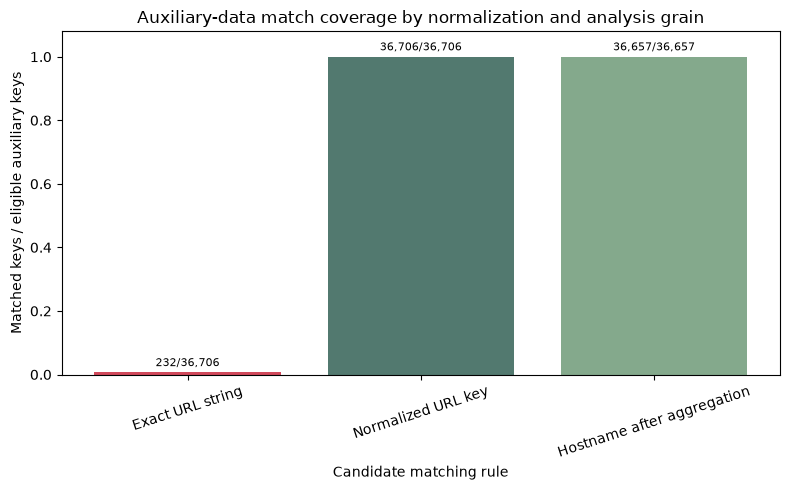

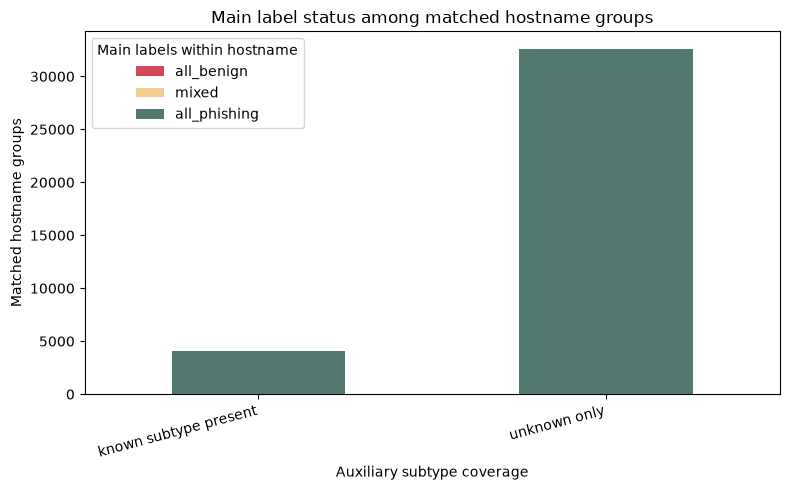

In [4]:
# Compare match coverage at the unit used by each rule. The host rule aggregates first.
match_summary = pd.DataFrame([
    {"rule": "Exact URL string", "matched": int(raw_exact["_merge"].eq("both").sum()), "eligible": len(aux), "unit": "auxiliary URL rows"},
    {"rule": "Normalized URL key", "matched": int(url_normalized["_merge"].eq("both").sum()), "eligible": len(aux), "unit": "auxiliary URL rows"},
    {"rule": "Hostname after aggregation", "matched": int(matched_hosts.shape[0]), "eligible": len(aux_hosts), "unit": "unique auxiliary hostnames"},
])
match_summary["coverage"] = match_summary["matched"] / match_summary["eligible"]
display(match_summary)

fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#d1495b", "#52796f", "#84a98c"]
bars = ax.bar(match_summary["rule"], match_summary["coverage"], color=colors)
ax.set_ylim(0, 1.08)
ax.set_title("Auxiliary-data match coverage by normalization and analysis grain")
ax.set_xlabel("Candidate matching rule")
ax.set_ylabel("Matched keys / eligible auxiliary keys")
ax.tick_params(axis="x", rotation=18)
for bar, row in zip(bars, match_summary.itertuples()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + .02, f"{row.matched:,}/{row.eligible:,}", ha="center", fontsize=8)
fig.tight_layout()
plt.show()

label_status_by_type = matched_hosts.groupby(["aux_type_group", "main_label_status"], observed=True).size().unstack(fill_value=0)
label_status_by_type = label_status_by_type.reindex(columns=["all_benign", "mixed", "all_phishing"], fill_value=0)
ax = label_status_by_type.plot(kind="bar", stacked=True, figsize=(8, 5), color=["#d1495b", "#f2cc8f", "#52796f"])
ax.set_title("Main label status among matched hostname groups")
ax.set_xlabel("Auxiliary subtype coverage")
ax.set_ylabel("Matched hostname groups")
ax.legend(title="Main labels within hostname")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

### Q5 — nhóm hoàn thiện

- Khóa chính và grain đã chọn, cùng lý do: `[tự viết]`
- Kết quả consistency theo URL-level và host-level, nêu rõ strict/lenient: `[tự viết]`
- Robustness theo exact/normalized URL và hostname aggregation: `[tự viết]`
- Hạn chế, đặc biệt ý nghĩa của `unknown` và host có nhiều URL/nhãn: `[tự viết]`

## Tổng hợp Q1–Q5 — nhóm tự viết

1. `[Phát hiện quan trọng 1]`
2. `[Phát hiện quan trọng 2]`
3. `[Phát hiện quan trọng 3]`
4. `[Phát hiện bất ngờ hoặc mâu thuẫn]`
5. `[Hạn chế chung và hướng nghiên cứu tiếp theo]`